# DINOv2 ViT-S/14: train on your own computer

The local version of `train_colab_dinov2.ipynb`. It runs the same scripts (`train.py` and `evaluate.py`) with the
same config (`config.yaml`), and saves to the same run names. So results from here and from Colab can be compared
and mixed. See `baseline/MultiTaskBaseline/DINOv2/README.md` for the model itself.

| Run | Output folder |
|---|---|
| Multi-task (one model, crop head + disease head) | `outputs/multitask_dinov2` |
| Independent crop model | `outputs/indep_crop_dinov2` |
| Independent disease model | `outputs/indep_disease_dinov2` |
| Evaluation | `outputs/multitask_dinov2/eval`, `outputs/indep_dinov2/eval` |

## Before the first run

1. **GPU:** an NVIDIA GPU with at least 4 GB of memory, and PyTorch with CUDA
   (`torch.cuda.is_available()` must be `True`).
   Batch 64 doesn't reliably fit on a 6 GB laptop GPU next to Windows, so by default this notebook feeds the
   GPU 32 images at a time and adds up the gradients of 2 batches before each update (`MICRO_BATCH`). The model
   still updates once per 64 images, like the Colab run. ViTs use LayerNorm, not BatchNorm, so the
   results stay comparable.
2. **Packages:** `pip install timm pyyaml pandas matplotlib scikit-learn tqdm`
3. **Dataset:** the 3 CSVs and the unpacked images go in the repo's `dataset/` folder:
   `dataset/DPD_Small_train.csv`, `dataset/DPD_Small_test_seen.csv`, `dataset/DPD_Small_test_unseen.csv`
   and `dataset/DPD_Small_dataset/*.jpg`.
4. The first run downloads the pretrained weights (~85 MB) from Hugging Face. A warning about a missing
   `HF_TOKEN` is safe to ignore.

Close other programs that use the GPU, keep a laptop plugged in, and turn off sleep while training.

## If training stops

Run all cells again. Finished runs are skipped. A run that was cut off restarts from epoch 1, because `train.py`
can't resume yet. Pressing **Stop** in Jupyter also stops the training process.

## Sharing with the team

1. When everything has run, **save this notebook** (Ctrl+S) so the logs, table and plots stay in it.
2. The last cell zips the 4 result folders (with `best.pt`) into `outputs/share_dinov2_local.zip`.
3. Upload the notebook and the zip to the team Drive. Unzip the folders into `AML_Group_Project/aml_runs`.
   The Colab notebook then sees the runs as finished and skips straight to the results.

## 1. Settings

In [1]:
# ===== Edit these =====
FORCE_RETRAIN = False   # True = train again even if a finished run is already in outputs/
MICRO_BATCH   = 32      # images per GPU step. Gradients are added up until the config's batch (64) is reached,
                        # so training matches Colab. Lower to 16 if you still run out of GPU memory.
                        # None = use config.yaml unchanged (batch 64 in one go).
SHARE_DIR     = None    # optional: a synced team folder, e.g. "G:/My Drive/AML_Group_Project/aml_runs".
                        # None = make a zip to upload by hand instead (last cell).
# ======================

MODEL_DIR = "baseline/MultiTaskBaseline/DINOv2"
CONFIG    = "baseline/MultiTaskBaseline/DINOv2/config.yaml"
RUNS = {
    "multitask": "multitask_dinov2",
    "crop":      "indep_crop_dinov2",
    "disease":   "indep_disease_dinov2",
}
INDEP_EVAL = "indep_dinov2"   # evaluation folder for the crop + disease pair

## 2. Check the repo, GPU and dataset

The scripts use paths relative to the repo root, so this cell moves there first. The GPU and library versions are
printed so the report can say where the model was trained. The GPU is checked from a separate process, so this
notebook never holds GPU memory that training needs.

In [2]:
import os
import platform
import subprocess
import sys

# Jupyter starts in this notebook's folder. Walk up to the repo root.
here = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(here, MODEL_DIR)):
    parent = os.path.dirname(here)
    if parent == here:
        raise FileNotFoundError(f"Can't find {MODEL_DIR}. Open this notebook from inside the project repo.")
    here = parent
os.chdir(here)
print("Repo root:", here)

r = subprocess.run(["git", "log", "-1", "--format=%h %s (%cr)"], capture_output=True, text=True)
print("Code version:", r.stdout.strip() or "unknown (git not found)")

PROBE = r"""
import torch
ok = torch.cuda.is_available()
free, total = torch.cuda.mem_get_info() if ok else (0, 0)
print(ok, torch.cuda.get_device_name(0) if ok else "-", free >> 20, total >> 20, torch.__version__, torch.version.cuda, sep="|")
"""
probe = subprocess.run([sys.executable, "-c", PROBE], capture_output=True, text=True)
assert probe.returncode == 0, f"Can't import torch in {sys.executable}:\n{probe.stderr}"
ok, GPU_NAME, free_mb, total_mb, torch_ver, cuda_ver = probe.stdout.strip().splitlines()[-1].split("|")
print(f"Python {platform.python_version()} ({sys.executable})")
print(f"torch {torch_ver} | CUDA {cuda_ver} | {platform.system()}")
assert ok == "True", ("No CUDA GPU found. This kernel has a CPU-only PyTorch: pick a kernel with CUDA PyTorch "
                      "(Select Kernel, top right) or install it, then run this cell again.")
free_gb, total_gb = int(free_mb) / 1024, int(total_mb) / 1024
print(f"GPU: {GPU_NAME} ({total_gb:.1f} GB, {free_gb:.1f} GB free)")
if free_gb < 4:
    print("Warning: under 4 GB free. Close programs that use the GPU (browser, games, video, other notebooks), "
          "or lower MICRO_BATCH to 16.")

import timm
print("timm", timm.__version__)

import pandas as pd

CSVS = ["DPD_Small_train.csv", "DPD_Small_test_seen.csv", "DPD_Small_test_unseen.csv"]
IMG_DIR = "dataset/DPD_Small_dataset"
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
missing = [n for n in CSVS if not os.path.isfile(f"dataset/{n}")]
assert not missing, f"Missing from dataset/: {missing}"
assert os.path.isdir(IMG_DIR), f"{IMG_DIR} not found. Unpack DPD_Small.7z there."

# Every image named in the CSVs must exist (first column; a header row, if any, is skipped).
names = pd.concat([pd.read_csv(f"dataset/{n}", header=None, usecols=[0])[0] for n in CSVS]).astype(str)
names = names[names.str.lower().str.endswith(IMG_EXT)]
have = set(os.listdir(IMG_DIR))
missing = [n for n in names if os.path.basename(n) not in have]
assert not missing, f"{len(missing)} images in the CSVs are missing, e.g. {missing[:3]}"
print(f"Images: {len(have)} (all {len(names)} CSV entries found)")

Repo root: c:\COS30082_ML_Project
Code version: 9c704df Add some description in readme.ipynb about metrics (27 hours ago)
Python 3.14.2 (c:\Users\USER\AppData\Local\Programs\Python\Python314\python.exe)
torch 2.14.1+cu126 | CUDA 12.6 | Windows
GPU: NVIDIA GeForce RTX 3060 Laptop GPU (6.0 GB, 5.0 GB free)


c:\Users\USER\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


timm 1.0.31
Images: 11448 (all 11448 CSV entries found)


## 3. Helpers

`train()` and `evaluate()` run the scripts as separate processes, with live output here. That also avoids a
Windows problem where data-loader workers crash when training code runs inside Jupyter itself.

In [3]:
import codecs
import csv

import yaml

os.makedirs("outputs", exist_ok=True)
with open(CONFIG) as f:
    CFG = yaml.safe_load(f)
EPOCHS, PATIENCE = CFG["train"]["epochs"], CFG["train"].get("patience", 0)

# Same effective batch as config.yaml, split into smaller GPU steps. Each run's saved config.yaml records this.
TRAIN_CONFIG = CONFIG
effective = CFG["train"]["batch_size"] * CFG["train"].get("accum_steps", 1)
if MICRO_BATCH and MICRO_BATCH != CFG["train"]["batch_size"]:
    assert effective % MICRO_BATCH == 0, f"MICRO_BATCH must divide the effective batch ({effective})"
    local = yaml.safe_load(open(CONFIG))
    local["train"]["batch_size"] = MICRO_BATCH
    local["train"]["accum_steps"] = effective // MICRO_BATCH
    TRAIN_CONFIG = "outputs/local_config_dinov2.yaml"
    with open(TRAIN_CONFIG, "w") as f:
        yaml.safe_dump(local, f, sort_keys=False)
tc = yaml.safe_load(open(TRAIN_CONFIG))["train"]
print(f"Training batch: {tc['batch_size']} x accum {tc.get('accum_steps', 1)} = {effective} per update ({TRAIN_CONFIG})\n")


def run_status(exp):
    """'done', 'partial' or 'missing' for a training run saved in outputs/."""
    hist = f"outputs/{exp}/history.csv"
    if not (os.path.isfile(hist) and os.path.isfile(f"outputs/{exp}/best.pt")):
        return "missing"
    with open(hist) as f:
        scores = [float(r["val_score"]) for r in csv.DictReader(f)]
    if not scores:
        return "partial"
    best_epoch = scores.index(max(scores)) + 1          # same rule as train.py
    early_stop = PATIENCE and len(scores) - best_epoch >= PATIENCE
    return "done" if len(scores) >= EPOCHS or early_stop else "partial"


def run(args):
    """Run a script with this notebook's Python and stream its output. Stop in Jupyter stops it too."""
    print("$", " ".join(args), flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8",
           "TQDM_MININTERVAL": "30"}   # fewer progress-bar updates keep the saved notebook small
    p = subprocess.Popen([sys.executable, *args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=env)
    decoder = codecs.getincrementaldecoder("utf-8")(errors="replace")
    try:
        while chunk := p.stdout.read1(4096):
            sys.stdout.write(decoder.decode(chunk))
            sys.stdout.flush()
    except KeyboardInterrupt:
        if os.name == "nt":   # also stop the data-loader worker processes
            subprocess.run(["taskkill", "/F", "/T", "/PID", str(p.pid)], capture_output=True)
        else:
            p.terminate()
        p.wait()
        raise
    if p.wait():
        raise RuntimeError("Command failed, see the error above.")


def train(mode):
    exp = RUNS[mode]
    status = run_status(exp)
    if status == "done" and not FORCE_RETRAIN:
        print(f"{exp}: already finished, skipping. Set FORCE_RETRAIN = True to train it again.")
        return
    if status == "partial":
        print(f"{exp}: found an unfinished run. Training restarts from epoch 1.")
    run([f"{MODEL_DIR}/train.py", "--config", TRAIN_CONFIG, "--mode", mode, "--experiment", exp])


def evaluate(modes, out_name):
    exps = [RUNS[m] for m in modes]
    not_done = [e for e in exps if run_status(e) != "done"]
    if not_done:
        print(f"Skipping {out_name}: training not finished for {not_done}")
        return
    ckpts = [f"outputs/{e}/best.pt" for e in exps]
    metrics = f"outputs/{out_name}/eval/metrics.json"
    if (os.path.isfile(metrics) and not FORCE_RETRAIN
            and os.path.getmtime(metrics) > max(os.path.getmtime(c) for c in ckpts)):
        print(f"{out_name}: already evaluated, skipping.")
        return
    run([f"{MODEL_DIR}/evaluate.py", "--checkpoints", *ckpts, "--out", f"outputs/{out_name}/eval",
         "--batch_size", "64"])   # smaller than the default 128 to fit the GPU; doesn't change the metrics


for exp in RUNS.values():
    print(f"{exp:28s} {run_status(exp)}")

Training batch: 32 x accum 2 = 64 per update (outputs/local_config_dinov2.yaml)

multitask_dinov2             partial
indep_crop_dinov2            missing
indep_disease_dinov2         missing


## 4. Train the multi-task model

In [4]:
train("multitask")

multitask_dinov2: found an unfinished run. Training restarts from epoch 1.
$ baseline/MultiTaskBaseline/DINOv2/train.py --config outputs/local_config_dinov2.yaml --mode multitask --experiment multitask_dinov2
[data] train=8000 test_seen=2000 test_unseen=1448
[data] crops=55 diseases=175 seen pairs=323 unseen pairs=10
[data] every unseen crop and disease appears in train -> compositional zero-shot setting
[data] images per seen pair: min=1 median=7 max=544
[data] train=7329 val=671
[model] vit_small_patch14_dinov2.lvd142m heads={'crop': 55, 'disease': 175} params=21.7M
[train] batch 32 x accum 2 = effective batch 64
train:   0%|          | 0/229 [00:00<?, ?it/s]c:\COS30082_ML_Project\baseline\MultiTaskBaseline\DINOv2\train.py:98: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first

## 5. Train the independent crop model

In [5]:
train("crop")

$ baseline/MultiTaskBaseline/DINOv2/train.py --config outputs/local_config_dinov2.yaml --mode crop --experiment indep_crop_dinov2
[data] train=8000 test_seen=2000 test_unseen=1448
[data] crops=55 diseases=175 seen pairs=323 unseen pairs=10
[data] every unseen crop and disease appears in train -> compositional zero-shot setting
[data] images per seen pair: min=1 median=7 max=544
[data] train=7329 val=671
[model] vit_small_patch14_dinov2.lvd142m heads={'crop': 55} params=21.6M
[train] batch 32 x accum 2 = effective batch 64
train:   0%|          | 0/229 [00:00<?, ?it/s]c:\COS30082_ML_Project\baseline\MultiTaskBaseline\DINOv2\train.py:98: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim

## 6. Train the independent disease model

In [6]:
train("disease")

$ baseline/MultiTaskBaseline/DINOv2/train.py --config outputs/local_config_dinov2.yaml --mode disease --experiment indep_disease_dinov2
[data] train=8000 test_seen=2000 test_unseen=1448
[data] crops=55 diseases=175 seen pairs=323 unseen pairs=10
[data] every unseen crop and disease appears in train -> compositional zero-shot setting
[data] images per seen pair: min=1 median=7 max=544
[data] train=7329 val=671
[model] vit_small_patch14_dinov2.lvd142m heads={'disease': 175} params=21.7M
[train] batch 32 x accum 2 = effective batch 64
train:   0%|          | 0/229 [00:00<?, ?it/s]c:\COS30082_ML_Project\baseline\MultiTaskBaseline\DINOv2\train.py:98: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/st

## 7. Evaluate on test_seen and test_unseen

In [7]:
evaluate(["multitask"], RUNS["multitask"])
evaluate(["crop", "disease"], INDEP_EVAL)

$ baseline/MultiTaskBaseline/DINOv2/evaluate.py --checkpoints outputs/multitask_dinov2/best.pt --out outputs/multitask_dinov2/eval --batch_size 64
[data] train=8000 test_seen=2000 test_unseen=1448
[data] crops=55 diseases=175 seen pairs=323 unseen pairs=10
[data] every unseen crop and disease appears in train -> compositional zero-shot setting
[data] images per seen pair: min=1 median=7 max=544
                                              
                       Top-1    Top-5
  seen crop                      0.9190   0.9750
  seen disease                   0.7335   0.9215
  seen composition               0.7185   0.9095
  seen composition_closed_world  0.7185   0.9105
unseen crop                      0.7507   0.8916
unseen disease                   0.0849   0.2735
unseen composition               0.0456   0.3149
unseen composition_closed_world  0.8094   0.9862
harmonic mean (composition)      0.0857   0.4678
calibrated best HM 0.6623 (seen 0.6080, unseen 0.7272, bias 6.506) | AUC 0.5

## 8. Results

Top-1 accuracy (trained locally on NVIDIA GeForce RTX 3060 Laptop GPU)


,seen crop,seen disease,seen pair,unseen crop,unseen disease,unseen pair,HM,best HM (calibrated),AUC
multitask_dinov2,0.919,0.7335,0.7185,0.7507,0.0849,0.0456,0.0857,0.6623,0.5453
indep_dinov2,0.920,0.7370,0.7270,0.7507,0.1043,0.1022,0.1792,0.6824,0.5539


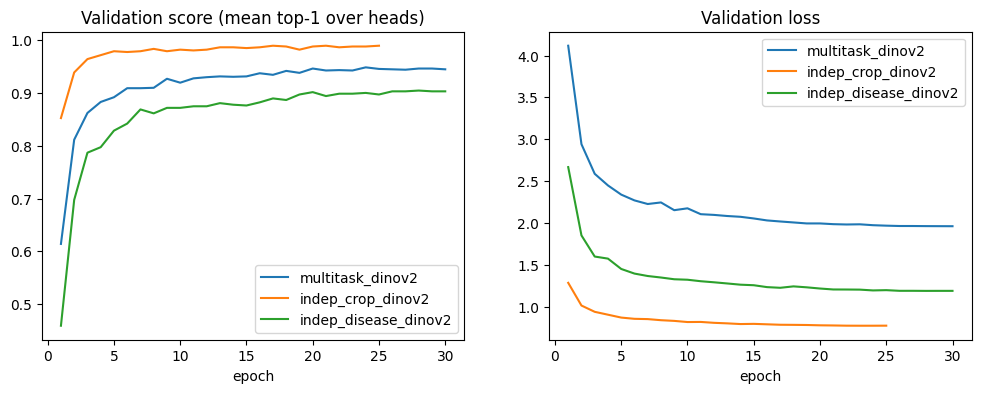

outputs/multitask_dinov2/eval/calibration_curve.png


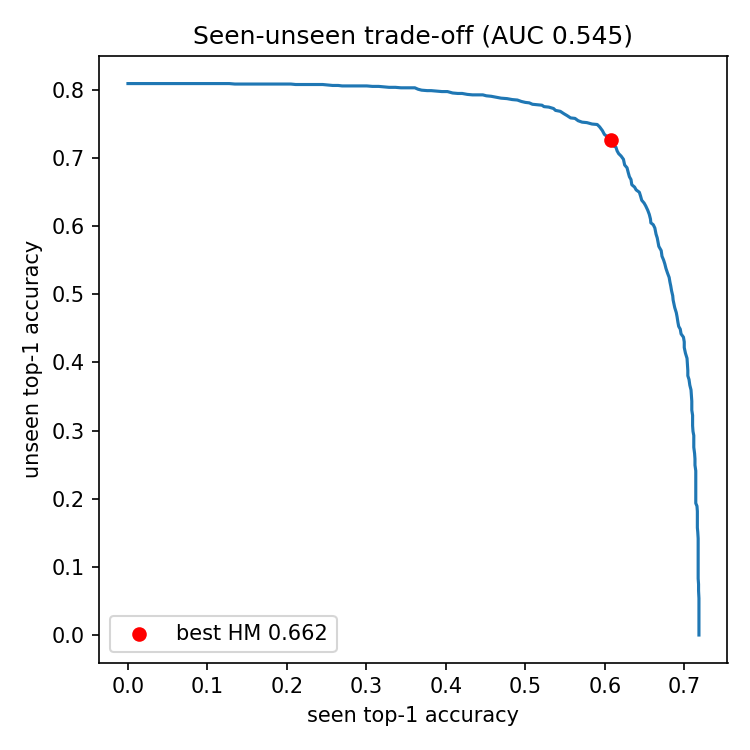

outputs/multitask_dinov2/eval/top_confusions_seen.png


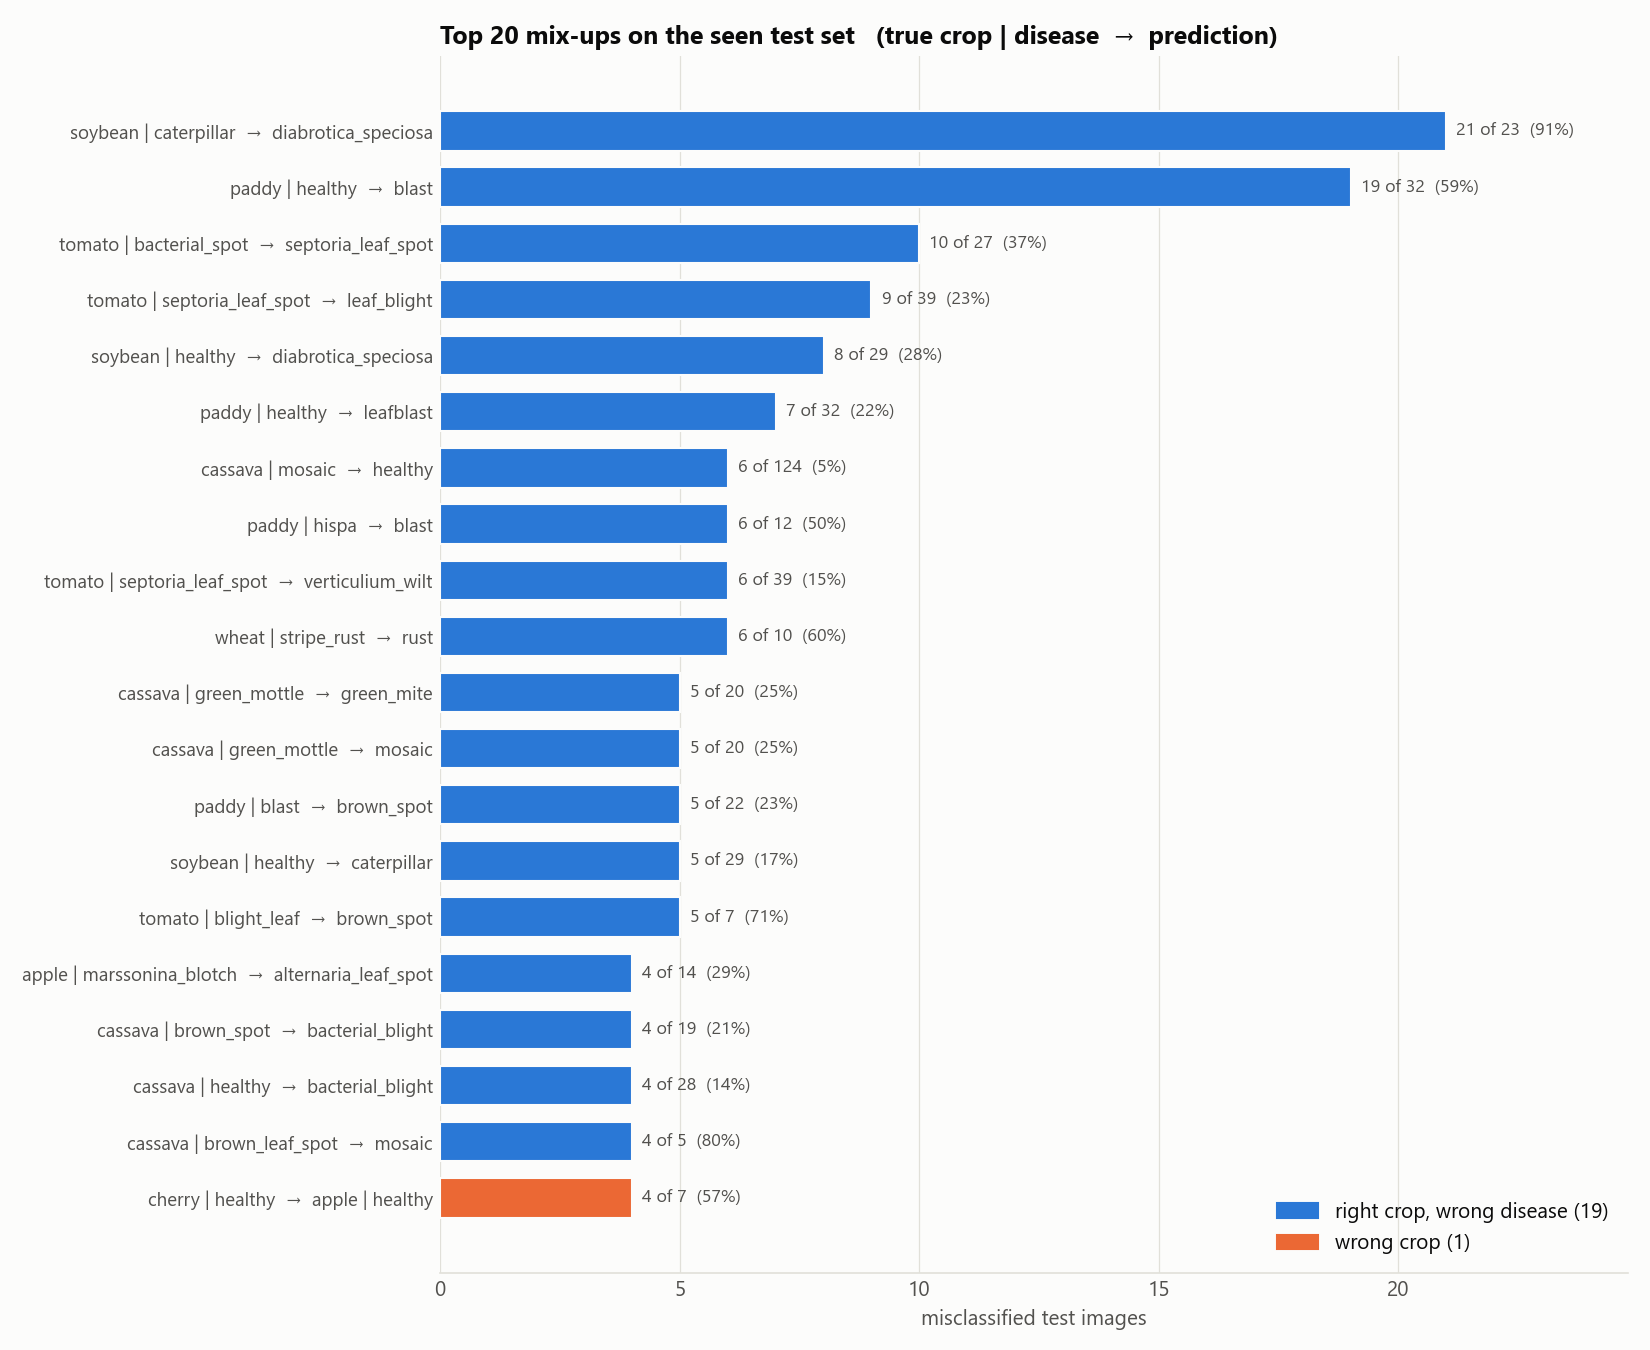

outputs/indep_dinov2/eval/calibration_curve.png


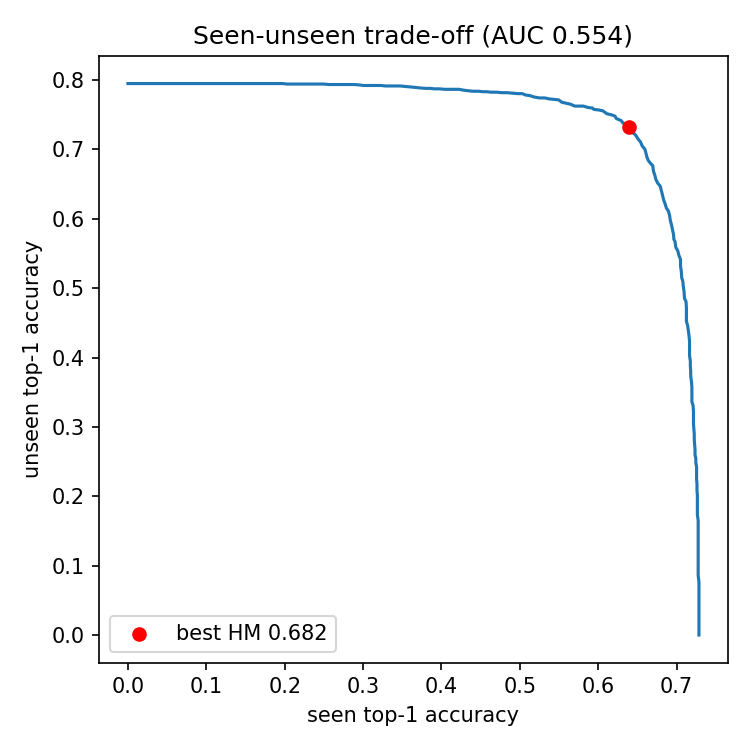

outputs/indep_dinov2/eval/top_confusions_seen.png


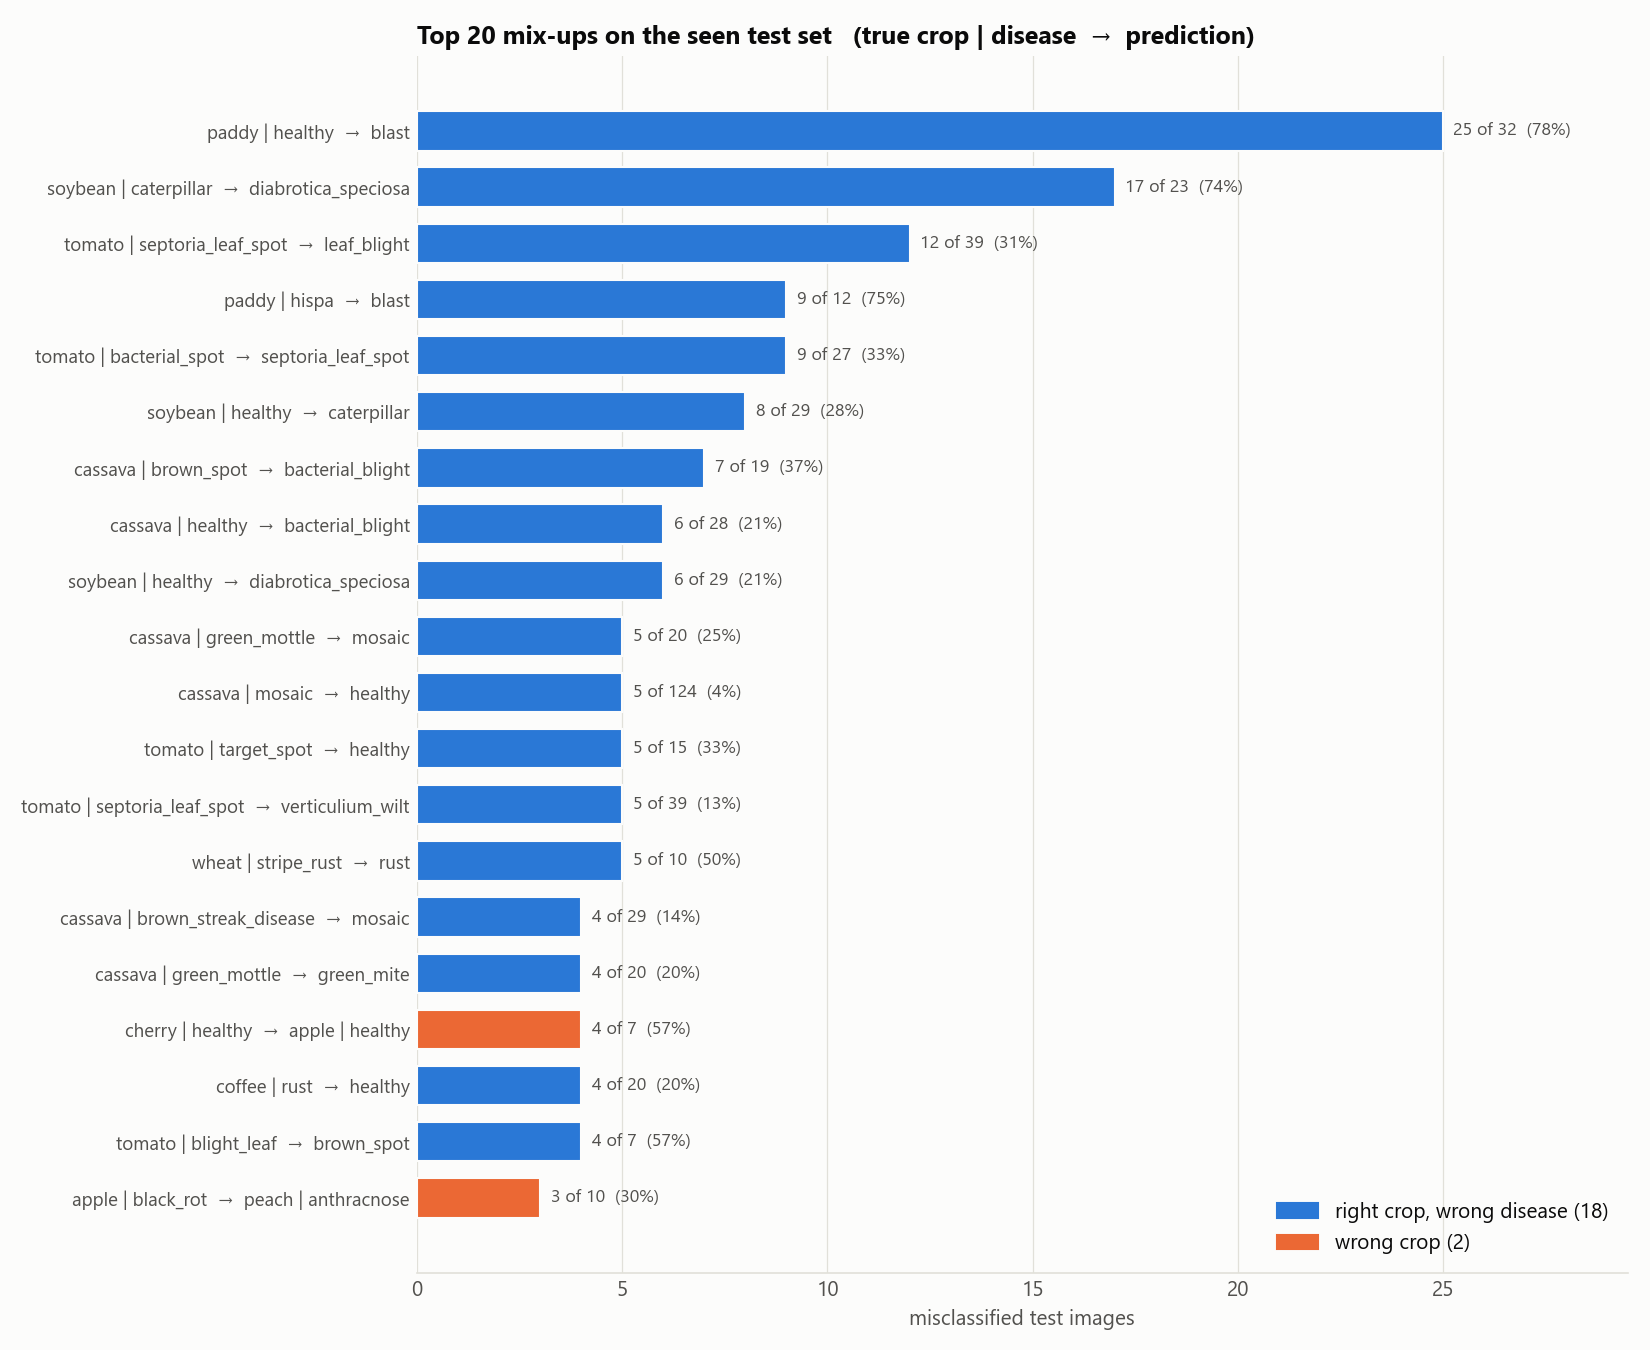

In [8]:
import json

import matplotlib.pyplot as plt
from IPython.display import Image, display

rows = {}
for name in [RUNS["multitask"], INDEP_EVAL]:
    path = f"outputs/{name}/eval/metrics.json"
    if not os.path.isfile(path):
        continue
    with open(path) as f:
        m = json.load(f)
    rows[name] = {
        "seen crop": m["seen"]["crop"]["top1"],
        "seen disease": m["seen"]["disease"]["top1"],
        "seen pair": m["seen"]["composition"]["top1"],
        "unseen crop": m["unseen"]["crop"]["top1"],
        "unseen disease": m["unseen"]["disease"]["top1"],
        "unseen pair": m["unseen"]["composition"]["top1"],
        "HM": m["harmonic_mean"]["top1"],
        "best HM (calibrated)": m["calibrated"]["best_hm"],
        "AUC": m["calibrated"]["auc"],
    }
if rows:
    print(f"Top-1 accuracy (trained locally on {GPU_NAME})")
    display(pd.DataFrame(rows).T.round(4))
else:
    print("No evaluation results yet.")

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for exp in RUNS.values():
    hist = f"outputs/{exp}/history.csv"
    if os.path.isfile(hist):
        h = pd.read_csv(hist)
        ax[0].plot(h["epoch"], h["val_score"], label=exp)
        ax[1].plot(h["epoch"], h["val_loss"], label=exp)
ax[0].set(title="Validation score (mean top-1 over heads)", xlabel="epoch")
ax[1].set(title="Validation loss", xlabel="epoch")
for a in ax:
    a.legend()
plt.show()

for name in [RUNS["multitask"], INDEP_EVAL]:
    for png in ["calibration_curve.png", "top_confusions_seen.png"]:
        path = f"outputs/{name}/eval/{png}"
        if os.path.isfile(path):
            print(path)
            display(Image(path, width=600))

## 9. Package the results for the team Drive

Collects the 4 result folders with `best.pt` (the Colab notebook needs it to see a run as finished). `last.pt` is
left out to save space. With `SHARE_DIR` set, the folders are copied there. Otherwise they are zipped into
`outputs/share_dinov2_local.zip`: upload it, then unzip the folders into `AML_Group_Project/aml_runs`.

The small result files (no checkpoints) can also be committed to git as usual. `.gitignore` already keeps the
`.pt` files out.

In [9]:
import shutil
import zipfile

names = list(RUNS.values()) + [INDEP_EVAL]
files = []
for name in names:
    for root, _, fs in os.walk(f"outputs/{name}"):
        files += [os.path.join(root, fn) for fn in fs if fn != "last.pt"]
assert files, "No results yet. Run the training cells first."

if SHARE_DIR:
    for p in files:
        dst = os.path.join(SHARE_DIR, os.path.relpath(p, "outputs"))
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy2(p, dst)
    print(f"Copied {len(files)} files to {SHARE_DIR}")
else:
    zip_path = "outputs/share_dinov2_local.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in files:
            z.write(p, os.path.relpath(p, "outputs"))
    print(f"{len(files)} files -> {os.path.abspath(zip_path)} ({os.path.getsize(zip_path) / 2**20:.0f} MB)")
print("Now save this notebook (Ctrl+S) and upload it too.")

25 files -> c:\COS30082_ML_Project\outputs\share_dinov2_local.zip (232 MB)
Now save this notebook (Ctrl+S) and upload it too.
